In [1]:
#THIS NOTEBOOK INVESTIGATES OUT OF DISTRIBUTION PREDICTIONS FOR BASELINE MODELS USING THE WYTTENBACH ET AL. 2020 DATASET OF MARKET DRUGS

import sys
sys.path.append("..")
from chemprop_utils import build_and_train_mpnn, predict_test_set
import pandas as pd
import pickle

import pandas as pd
import requests
import time

#TABLE 2 DATA — MARKET DRUGS, TRANSCRIBED FROM WYTTENBACH ET AL. 2020, MOL. PHARMACEUTICS 17(7), 2660-2671
#FORMAT: (compound_name, Tm_K, dHf_kJmol)
market_drugs = [
    ("aceclofenac", 426.2, 42.3), ("cinnarizine", 394.2, 40.9), ("ibuprofen", 350.2, 26.5), ("phenylbutazone", 379.6, 28.1),
    ("acemetacin", 421.0, 48.0), ("clofibric acid", 394.6, 29.0), ("indomethacin", 434.2, 37.6), ("physostigmine", 377.0, 32.0),
    ("acetaminophen", 443.0, 29.0), ("clofoctol", 361.2, 35.2), ("indoprofen", 485.3, 37.3), ("pimozide", 492.0, 42.7),
    ("anthranilic acid", 420.2, 22.9), ("clotrimazole", 418.0, 35.0), ("isradipine", 432.0, 34.0), ("piroxicam", 473.9, 35.6),
    ("antipyrin", 384.2, 25.2), ("salicin", 474.2, 52.8), ("itraconazole", 441.2, 57.6), ("probenecid", 472.2, 40.4),
    ("atenolol", 426.2, 37.5), ("danazol", 500.0, 36.0), ("ketoconazole", 423.2, 52.9), ("probucol", 400.2, 34.2),
    ("atovaquone", 492.2, 33.5), ("diflunisal", 485.9, 35.6), ("ketoprofen", 368.2, 28.3), ("procaine", 333.6, 26.1),
    ("benzamide", 400.2, 21.7), ("droperidol", 416.2, 40.0), ("lacidipine", 452.7, 42.8), ("saccharin", 501.0, 29.5),
    ("benzocaine", 362.2, 22.6), ("emtricitabine", 426.0, 27.0), ("lidocaine", 341.2, 16.7), ("salicylic acid", 432.4, 24.9),
    ("bezafibrate", 458.8, 49.2), ("ezetimibe", 437.0, 40.0), ("loratadine", 409.2, 27.3), ("simvastatin", 412.0, 29.0),
    ("bicalutamide", 465.0, 52.9), ("felbinac", 437.2, 29.8), ("mefenamic acid", 504.5, 39.4), ("spironolactone", 486.0, 24.0),
    ("bifonazole", 424.2, 39.2), ("felodipine", 420.2, 31.0), ("metolazone", 539.0, 36.0), ("sulindac", 460.0, 32.0),
    ("bucindolol", 459.0, 38.0), ("fenofibrate", 354.2, 33.0), ("miconazole", 359.2, 32.8), ("tamoxifen", 371.0, 56.0),
    ("budesonide", 530.0, 39.0), ("flufenamic acid", 408.2, 27.1), ("nandrolone", 397.0, 21.0), ("terfenadine", 422.9, 51.9),
    ("caffeine", 510.2, 20.8), ("fluorescamine", 426.0, 28.0), ("naproxen", 429.9, 32.4), ("testosterone", 426.0, 26.0),
    ("captopril", 380.0, 29.0), ("flurbiprofen", 388.0, 28.0), ("nepafenac", 456.2, 42.8), ("theophylline", 545.2, 29.6),
    ("carbamazepine", 465.2, 25.5), ("glafenine", 437.0, 32.4), ("nifedipine", 446.0, 39.0), ("tolazamide", 445.0, 41.0),
    ("carvedilol", 390.0, 53.0), ("glibenclamide", 445.0, 51.0), ("nilutamide", 428.2, 31.0), ("tolbutamide", 402.2, 26.2),
    ("celecoxib", 436.0, 32.0), ("griseofulvin", 491.2, 39.1), ("nimesulide", 422.0, 32.7), ("tolfenamic acid", 486.2, 38.8),
    ("chlorpromazine", 331.9, 26.7), ("haloperidol", 425.2, 54.3), ("nitrendipine", 430.5, 39.0), ("warfarin", 435.0, 45.0),
    ("chlorzoxazone", 463.8, 25.5), ("hydrochlorothiazide", 536.0, 34.0), ("nizatidine", 406.0, 45.0), ("zolmitriptan", 410.0, 34.0),
    ("chlorpropamide", 397.2, 27.4), ("hydrocortisone", 492.7, 39.6), ("orlistat", 316.0, 56.0),
    ("cimetidine", 414.1, 40.8), ("hydroflumethiazide", 542.0, 39.0), ("phenacetin", 409.2, 31.5),
]

print(f"Total compounds transcribed: {len(market_drugs)}")  #SHOULD PRINT 90, MATCHING THE PAPER'S STATED n=90

#PUBCHEM NAME-TO-SMILES LOOKUP
def name_to_smiles(name):
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{name}/property/CanonicalSMILES/TXT"
    try:
        r = requests.get(url, timeout=10)
        if r.status_code == 200:
            return r.text.strip()
    except Exception:
        pass
    return None

records = []
for name, tm, dhf in market_drugs:
    smi = name_to_smiles(name)
    records.append({"compound": name, "smiles": smi, "Tm_K": tm, "dHf_kJmol": dhf})
    print(f"{name}: {'OK' if smi else 'FAILED'}")
    time.sleep(0.3)  #POLITE RATE LIMITING FOR PUBCHEM'S API

df_wyttenbach = pd.DataFrame(records)
n_matched = df_wyttenbach["smiles"].notna().sum()
print(f"\nSuccessfully matched: {n_matched} / {len(df_wyttenbach)}")

failed = df_wyttenbach[df_wyttenbach["smiles"].isna()]
if len(failed) > 0:
    print("\nFailed lookups (may need manual SMILES entry or name correction):")
    print(failed["compound"].tolist())

df_wyttenbach.to_csv("RAW DATA/wyttenbach_market_drugs.csv", index=False)
print("\nSaved to RAW DATA/wyttenbach_market_drugs.csv")


Total compounds transcribed: 90
aceclofenac: OK
cinnarizine: OK
ibuprofen: OK
phenylbutazone: OK
acemetacin: OK
clofibric acid: OK
indomethacin: OK
physostigmine: OK
acetaminophen: OK
clofoctol: OK
indoprofen: OK
pimozide: OK
anthranilic acid: OK
clotrimazole: OK
isradipine: OK
piroxicam: OK
antipyrin: OK
salicin: OK
itraconazole: OK
probenecid: OK
atenolol: OK
danazol: OK
ketoconazole: OK
probucol: OK
atovaquone: OK
diflunisal: OK
ketoprofen: OK
procaine: OK
benzamide: OK
droperidol: OK
lacidipine: OK
saccharin: OK
benzocaine: OK
emtricitabine: OK
lidocaine: OK
salicylic acid: OK
bezafibrate: OK
ezetimibe: OK
loratadine: OK
simvastatin: OK
bicalutamide: OK
felbinac: OK
mefenamic acid: OK
spironolactone: OK
bifonazole: OK
felodipine: OK
metolazone: OK
sulindac: OK
bucindolol: OK
fenofibrate: OK
miconazole: OK
tamoxifen: OK
budesonide: OK
flufenamic acid: OK
nandrolone: OK
terfenadine: OK
caffeine: OK
fluorescamine: OK
naproxen: OK
testosterone: OK
captopril: OK
flurbiprofen: OK
nepafen

In [2]:
KJ_TO_KCAL = 1 / 4.184

df_wyttenbach = pd.read_csv("RAW DATA/wyttenbach_market_drugs.csv")
df_wyttenbach["dHf_kcalmol"] = df_wyttenbach["dHf_kJmol"] * KJ_TO_KCAL

df_wyttenbach.to_csv("RAW DATA/wyttenbach_market_drugs.csv", index=False)
print(df_wyttenbach[["compound", "dHf_kJmol", "dHf_kcalmol"]].head())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors

df_wyttenbach = pd.read_csv("RAW DATA/wyttenbach_market_drugs.csv")

#VALIDATION — SAME CHECKS AS 01_data_validation.ipynb
print("NaN SMILES:", df_wyttenbach["smiles"].isna().sum())
print("NaN Tm:", df_wyttenbach["Tm_K"].isna().sum())
print("NaN dHf:", df_wyttenbach["dHf_kcalmol"].isna().sum())

df_wyttenbach = df_wyttenbach.dropna(subset=["smiles", "Tm_K", "dHf_kcalmol"]).reset_index(drop=True)
print(f"After dropping NaN: {len(df_wyttenbach)} compounds remain")

def sanitize_smiles(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    try:
        Chem.RemoveStereochemistry(mol)
        return Chem.MolToSmiles(mol)
    except Exception:
        return None

df_wyttenbach["smiles"] = df_wyttenbach["smiles"].apply(sanitize_smiles)
n_invalid = df_wyttenbach["smiles"].isna().sum()
print(f"Unparseable/unsanitizable SMILES: {n_invalid}")
df_wyttenbach = df_wyttenbach.dropna(subset=["smiles"]).reset_index(drop=True)

print(f"\nTm range: {df_wyttenbach['Tm_K'].min():.1f} - {df_wyttenbach['Tm_K'].max():.1f} K")
print(f"dHf range: {df_wyttenbach['dHf_kcalmol'].min():.2f} - {df_wyttenbach['dHf_kcalmol'].max():.2f} kcal/mol")

df_wyttenbach["MW"] = df_wyttenbach["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))
print(f"MW range: {df_wyttenbach['MW'].min():.1f} - {df_wyttenbach['MW'].max():.1f} g/mol")



         compound  dHf_kJmol  dHf_kcalmol
0     aceclofenac       42.3    10.109943
1     cinnarizine       40.9     9.775335
2       ibuprofen       26.5     6.333652
3  phenylbutazone       28.1     6.716061
4      acemetacin       48.0    11.472275
NaN SMILES: 0
NaN Tm: 0
NaN dHf: 0
After dropping NaN: 90 compounds remain
Unparseable/unsanitizable SMILES: 0

Tm range: 316.0 - 545.2 K
dHf range: 3.99 - 13.77 kcal/mol
MW range: 121.1 - 705.6 g/mol


[09:00:18] WARNING: not removing hydrogen atom without neighbors
[09:00:18] WARNING: not removing hydrogen atom without neighbors
[09:00:18] WARNING: not removing hydrogen atom without neighbors
[09:00:18] WARNING: not removing hydrogen atom without neighbors
[09:00:18] WARNING: not removing hydrogen atom without neighbors
[09:00:18] WARNING: not removing hydrogen atom without neighbors
[09:00:18] WARNING: not removing hydrogen atom without neighbors
[09:00:18] Unusual charge on atom 6 number of radical electrons set to zero


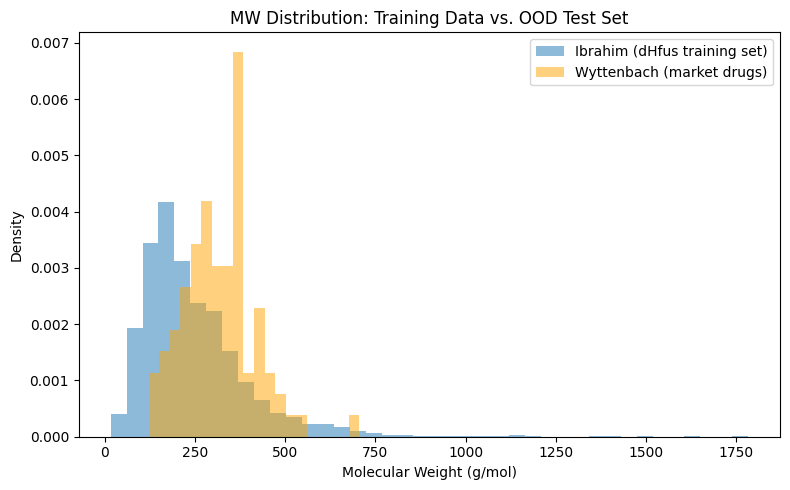

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


Ibrahim training median MW: 212.1
Wyttenbach median MW: 314.3
                      Method  Tm_RMSE_K  dHf_RMSE_kcalmol
Joback & Reid (classical GC)     204.01          2.514340
 COSMOquick (modern ML/QSPR)      22.43          1.584608


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


dHfus OOD — MAE: 1.837, RMSE: 2.393


In [3]:

dhfus_train_predictions = pd.read_csv("dHfus_baseline_train_predictions.csv")
dhfus_train_predictions["MW"] = dhfus_train_predictions["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(dhfus_train_predictions["MW"], bins=40, alpha=0.5, label="Ibrahim (dHfus training set)", density=True)
ax.hist(df_wyttenbach["MW"], bins=20, alpha=0.5, label="Wyttenbach (market drugs)", density=True, color="orange")
ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Density")
ax.set_title("MW Distribution: Training Data vs. OOD Test Set")
ax.legend()
plt.tight_layout()
plt.savefig("plots_wyttenbach_MW_vs_training.png", dpi=150)
plt.show()

print(f"Ibrahim training median MW: {dhfus_train_predictions['MW'].median():.1f}")
print(f"Wyttenbach median MW: {df_wyttenbach['MW'].median():.1f}")


paper_benchmarks = pd.DataFrame({
    "Method": ["Joback & Reid (classical GC)", "COSMOquick (modern ML/QSPR)"],
    "Tm_RMSE_K": [204.01, 22.43],
    "dHf_RMSE_kcalmol": [10.52 / 4.184, 6.63 / 4.184],   #CONVERTED FROM kJ/mol
})
print(paper_benchmarks.to_string(index=False))

from chemprop_utils import predict_external_set

dhfus_ood_predictions = predict_external_set(
    checkpoint_path="checkpoints/dHfus_OFFICIAL_BASELINE/" + [f for f in __import__("os").listdir("checkpoints/dHfus_OFFICIAL_BASELINE") if f.endswith(".ckpt")][0],
    smiles_list=df_wyttenbach["smiles"].tolist(),
    y_true_list=df_wyttenbach["dHf_kcalmol"].tolist(),
    run_name="dHfus_OOD_wyttenbach",
)
print(f"dHfus OOD — MAE: {dhfus_ood_predictions['abs_error'].mean():.3f}, RMSE: {np.sqrt((dhfus_ood_predictions['abs_error']**2).mean()):.3f}")

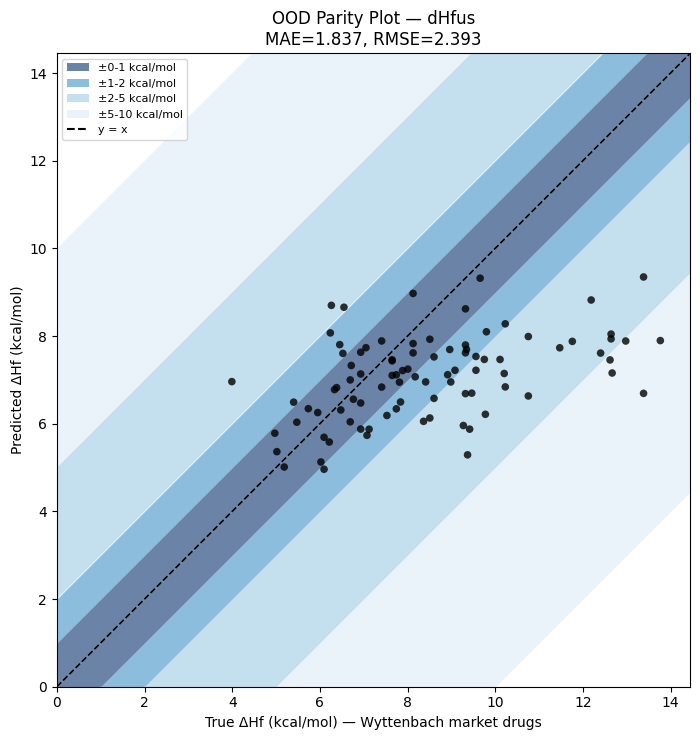

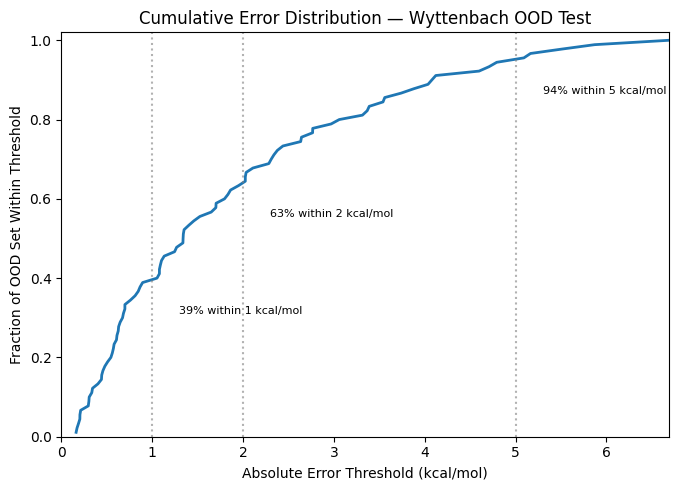

Band (kcal/mol)  Count  Percentage  Cumulative %
            0-1     35        38.9          38.9
            1-2     22        24.4          63.3
            2-5     28        31.1          94.4
           5-10      5         5.6         100.0
            >10      0         0.0         100.0


In [4]:

import matplotlib.pyplot as plt
#OOD PARITY PLOT WITH SHADED ERROR BANDS
fig, ax = plt.subplots(figsize=(7.5, 7.5))
max_val = max(dhfus_ood_predictions["y_true"].max(), dhfus_ood_predictions["y_pred"].max()) * 1.05
x_line = np.linspace(0, max_val, 200)

#SAME BAND WIDTHS AS THE dHfus BASELINE PARITY PLOT, FOR DIRECT VISUAL COMPARABILITY
bands = [(0, 1, "#08306b"), (1, 2, "#4292c6"), (2, 5, "#9ecae1"), (5, 10, "#deebf7")]
for lo, hi, color in bands:
    ax.fill_between(x_line, x_line + lo, x_line + hi, color=color, alpha=0.6, linewidth=0)
    ax.fill_between(x_line, np.maximum(x_line - hi, 0), np.maximum(x_line - lo, 0), color=color, alpha=0.6, linewidth=0)

ax.plot(x_line, x_line, "k--", linewidth=1.2, label="y = x", zorder=5)
ax.scatter(dhfus_ood_predictions["y_true"], dhfus_ood_predictions["y_pred"], color="black", s=30, alpha=0.8, zorder=6, edgecolor="none")

mae_ood = dhfus_ood_predictions["abs_error"].mean()
rmse_ood = np.sqrt((dhfus_ood_predictions["abs_error"] ** 2).mean())

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, alpha=0.6, label=f"±{lo}-{hi} kcal/mol") for lo, hi, c in bands]
legend_elements.append(plt.Line2D([0], [0], color="black", linestyle="--", label="y = x"))
ax.legend(handles=legend_elements, loc="upper left", fontsize=8)

ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel("True ΔHf (kcal/mol) — Wyttenbach market drugs")
ax.set_ylabel("Predicted ΔHf (kcal/mol)")
ax.set_title(f"OOD Parity Plot — dHfus\nMAE={mae_ood:.3f}, RMSE={rmse_ood:.3f}")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("plots_wyttenbach_dHfus_parity_bands.png", dpi=150)
plt.show()


#CUMULATIVE ERROR DISTRIBUTION CURVE — SAME STYLE AS THE BASELINE'S
sorted_errors_ood = np.sort(dhfus_ood_predictions["abs_error"])
cumulative_frac_ood = np.arange(1, len(sorted_errors_ood) + 1) / len(sorted_errors_ood)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sorted_errors_ood, cumulative_frac_ood, linewidth=2)
for threshold in [1, 2, 5]:
    frac_within = (dhfus_ood_predictions["abs_error"] <= threshold).mean()
    ax.axvline(threshold, color="gray", linestyle=":", alpha=0.6)
    ax.annotate(f"{frac_within:.0%} within {threshold} kcal/mol", xy=(threshold, frac_within),
                xytext=(threshold + 0.3, frac_within - 0.08), fontsize=8)
ax.set_xlabel("Absolute Error Threshold (kcal/mol)")
ax.set_ylabel("Fraction of OOD Set Within Threshold")
ax.set_title("Cumulative Error Distribution — Wyttenbach OOD Test")
ax.set_xlim(0, sorted_errors_ood.max())
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig("plots_wyttenbach_dHfus_cumulative_error.png", dpi=150)
plt.show()


#ERROR-BAND PERCENTAGE TABLE, SAME BINS AS THE PARITY PLOT'S SHADED BANDS
ood_bins = [0, 1, 2, 5, 10, np.inf]
ood_labels = ["0-1", "1-2", "2-5", "5-10", ">10"]
dhfus_ood_predictions["error_band"] = pd.cut(dhfus_ood_predictions["abs_error"], bins=ood_bins, labels=ood_labels, right=True)

ood_band_counts = dhfus_ood_predictions["error_band"].value_counts().reindex(ood_labels)
ood_band_pct = (ood_band_counts / len(dhfus_ood_predictions) * 100)
ood_cumulative_pct = ood_band_pct.cumsum()

ood_error_band_table = pd.DataFrame({
    "Band (kcal/mol)": ood_labels, "Count": ood_band_counts.values,
    "Percentage": ood_band_pct.round(1).values, "Cumulative %": ood_cumulative_pct.round(1).values,
})
print(ood_error_band_table.to_string(index=False))
ood_error_band_table.to_csv("dHfus_ood_error_bands.csv", index=False)


               Method     RMSE
Joback & Reid (paper) 2.514340
   COSMOquick (paper) 1.584608
 Baseline Model (OOD) 2.392590


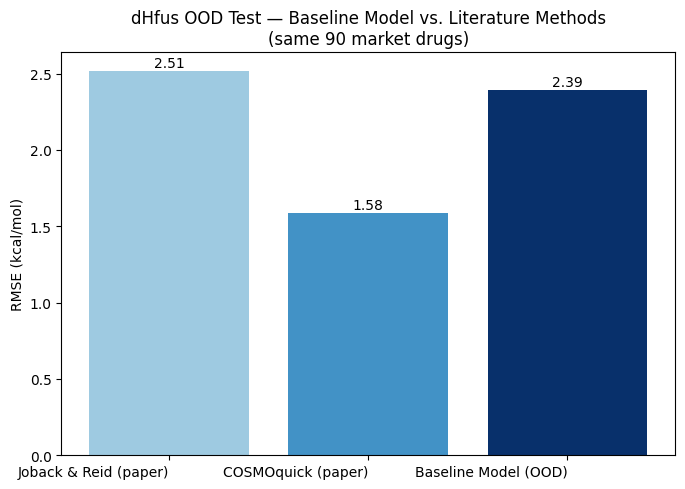

In [9]:
comparison_rows = [
    {"Method": "Joback & Reid (paper)", "RMSE": paper_benchmarks.loc[0, "dHf_RMSE_kcalmol"]},
    {"Method": "COSMOquick (paper)", "RMSE": paper_benchmarks.loc[1, "dHf_RMSE_kcalmol"]},
    {"Method": "Baseline Model (OOD)", "RMSE": rmse_ood},
]
ood_comparison_df = pd.DataFrame(comparison_rows)
print(ood_comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#9ecae1", "#4292c6", "#08306b"]
bars = ax.bar(ood_comparison_df["Method"], ood_comparison_df["RMSE"], color=colors)
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)
ax.set_ylabel("RMSE (kcal/mol)")
ax.set_title("dHfus OOD Test — Baseline Model vs. Literature Methods\n(same 90 market drugs)")
plt.xticks(rotation=0, ha="right")
plt.tight_layout()
plt.savefig("plots_wyttenbach_dHfus_method_comparison.png", dpi=150)
plt.show()


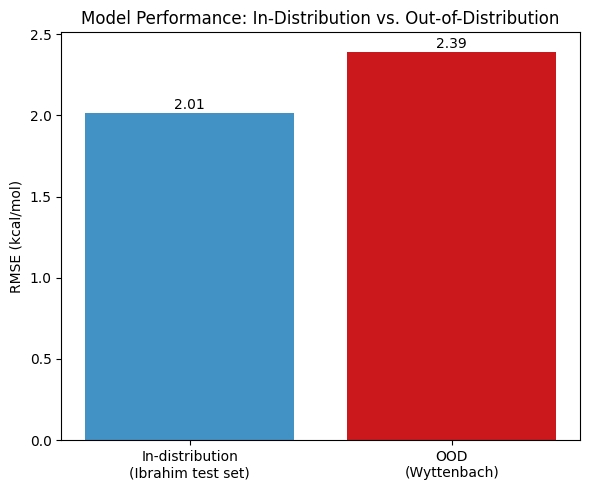

OOD RMSE is +18.8% relative to in-distribution RMSE


In [6]:
dhfus_baseline_predictions = pd.read_csv("dHfus_baseline_predictions.csv")

comparison_rows_id_ood = [
    {"Setting": "In-distribution\n(Ibrahim test set)", "RMSE": np.sqrt((dhfus_baseline_predictions["abs_error"]**2).mean())},
    {"Setting": "OOD\n(Wyttenbach)", "RMSE": rmse_ood},
]
id_ood_df = pd.DataFrame(comparison_rows_id_ood)

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(id_ood_df["Setting"], id_ood_df["RMSE"], color=["#4292c6", "#cb181d"])
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)
ax.set_ylabel("RMSE (kcal/mol)")
ax.set_title("Model Performance: In-Distribution vs. Out-of-Distribution")
plt.tight_layout()
plt.savefig("plots_wyttenbach_id_vs_ood.png", dpi=150)
plt.show()

degradation_pct = (rmse_ood - id_ood_df.loc[0, "RMSE"]) / id_ood_df.loc[0, "RMSE"] * 100
print(f"OOD RMSE is {degradation_pct:+.1f}% relative to in-distribution RMSE")



GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value o

Tm OOD — MAE: 27.058, RMSE: 33.551


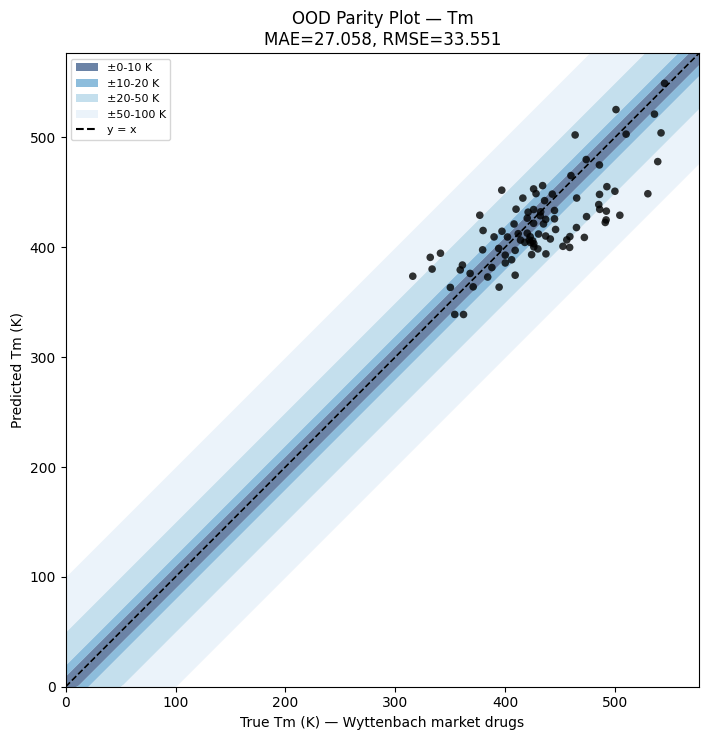

               Method       RMSE
Joback & Reid (paper) 204.010000
   COSMOquick (paper)  22.430000
 Baseline Model (OOD)  33.550809


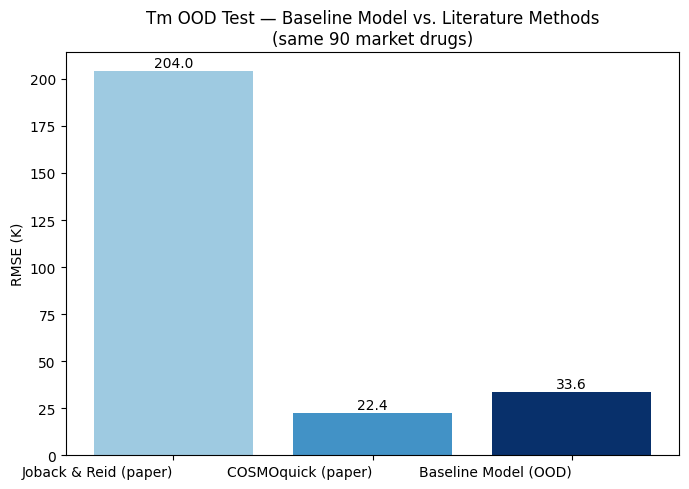

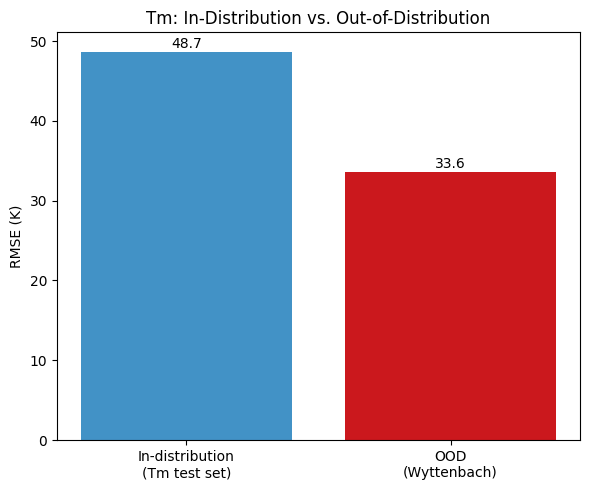

Tm OOD RMSE is -31.0% relative to in-distribution RMSE
Wyttenbach Tm range: 316.0 - 545.2, median: 426.2
Tm ID test range: 101.1 - 631.6, median: 414.6


In [11]:
#TM PREDICTION ON WYTTENBACH DATA (assuming you already ran this earlier — if not, run first)
import os
tm_ckpt_dir = "checkpoints/Tm_OFFICIAL_BASELINE"
tm_ckpt = tm_ckpt_dir + "/" + [f for f in os.listdir(tm_ckpt_dir) if f.endswith(".ckpt")][0]

tm_ood_predictions = predict_external_set(
    checkpoint_path=tm_ckpt,
    smiles_list=df_wyttenbach["smiles"].tolist(),
    y_true_list=df_wyttenbach["Tm_K"].tolist(),
    run_name="Tm_OOD_wyttenbach",
)
mae_tm_ood = tm_ood_predictions["abs_error"].mean()
rmse_tm_ood = np.sqrt((tm_ood_predictions["abs_error"] ** 2).mean())
print(f"Tm OOD — MAE: {mae_tm_ood:.3f}, RMSE: {rmse_tm_ood:.3f}")


#TM OOD PARITY PLOT WITH SHADED ERROR BANDS
fig, ax = plt.subplots(figsize=(7.5, 7.5))
max_val = max(tm_ood_predictions["y_true"].max(), tm_ood_predictions["y_pred"].max()) * 1.05
x_line = np.linspace(0, max_val, 200)

#SAME BAND WIDTHS AS THE Tm BASELINE PARITY PLOT, FOR DIRECT VISUAL COMPARABILITY
bands = [(0, 10, "#08306b"), (10, 20, "#4292c6"), (20, 50, "#9ecae1"), (50, 100, "#deebf7")]
for lo, hi, color in bands:
    ax.fill_between(x_line, x_line + lo, x_line + hi, color=color, alpha=0.6, linewidth=0)
    ax.fill_between(x_line, np.maximum(x_line - hi, 0), np.maximum(x_line - lo, 0), color=color, alpha=0.6, linewidth=0)

ax.plot(x_line, x_line, "k--", linewidth=1.2, label="y = x", zorder=5)
ax.scatter(tm_ood_predictions["y_true"], tm_ood_predictions["y_pred"], color="black", s=30, alpha=0.8, zorder=6, edgecolor="none")

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, alpha=0.6, label=f"±{lo}-{hi} K") for lo, hi, c in bands]
legend_elements.append(plt.Line2D([0], [0], color="black", linestyle="--", label="y = x"))
ax.legend(handles=legend_elements, loc="upper left", fontsize=8)

ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel("True Tm (K) — Wyttenbach market drugs")
ax.set_ylabel("Predicted Tm (K)")
ax.set_title(f"OOD Parity Plot — Tm\nMAE={mae_tm_ood:.3f}, RMSE={rmse_tm_ood:.3f}")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("plots_wyttenbach_Tm_parity_bands.png", dpi=150)
plt.show()


#CUMULATIVE ERROR DISTRIBUTION CURVE — TM OOD
sorted_errors_tm_ood = np.sort(tm_ood_predictions["abs_error"])
cumulative_frac_tm_ood = np.arange(1, len(sorted_errors_tm_ood) + 1) / len(sorted_errors_tm_ood)


#TM: YOUR MODEL VS JOBACK VS COSMOQUICK
tm_comparison_rows = [
    {"Method": "Joback & Reid (paper)", "RMSE": paper_benchmarks.loc[0, "Tm_RMSE_K"]},
    {"Method": "COSMOquick (paper)", "RMSE": paper_benchmarks.loc[1, "Tm_RMSE_K"]},
    {"Method": "Baseline Model (OOD)", "RMSE": rmse_tm_ood},
]
tm_ood_comparison_df = pd.DataFrame(tm_comparison_rows)
print(tm_ood_comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#9ecae1", "#4292c6", "#08306b"]
bars = ax.bar(tm_ood_comparison_df["Method"], tm_ood_comparison_df["RMSE"], color=colors)
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}", xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)
ax.set_ylabel("RMSE (K)")
ax.set_title("Tm OOD Test — Baseline Model vs. Literature Methods\n(same 90 market drugs)")
plt.xticks(rotation=0, ha="right")
plt.tight_layout()
plt.savefig("plots_wyttenbach_Tm_method_comparison.png", dpi=150)
plt.show()


#TM: IN-DISTRIBUTION VS OOD
tm_baseline_predictions = pd.read_csv("Tm_baseline_predictions.csv")

tm_id_ood_rows = [
    {"Setting": "In-distribution\n(Tm test set)", "RMSE": np.sqrt((tm_baseline_predictions["abs_error"]**2).mean())},
    {"Setting": "OOD\n(Wyttenbach)", "RMSE": rmse_tm_ood},
]
tm_id_ood_df = pd.DataFrame(tm_id_ood_rows)

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(tm_id_ood_df["Setting"], tm_id_ood_df["RMSE"], color=["#4292c6", "#cb181d"])
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.1f}", xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)
ax.set_ylabel("RMSE (K)")
ax.set_title("Tm: In-Distribution vs. Out-of-Distribution")
plt.tight_layout()
plt.savefig("plots_wyttenbach_Tm_id_vs_ood.png", dpi=150)
plt.show()

tm_degradation_pct = (rmse_tm_ood - tm_id_ood_df.loc[0, "RMSE"]) / tm_id_ood_df.loc[0, "RMSE"] * 100
print(f"Tm OOD RMSE is {tm_degradation_pct:+.1f}% relative to in-distribution RMSE")

print(f"Wyttenbach Tm range: {df_wyttenbach['Tm_K'].min():.1f} - {df_wyttenbach['Tm_K'].max():.1f}, median: {df_wyttenbach['Tm_K'].median():.1f}")
tm_test_true = tm_baseline_predictions["y_true"]
print(f"Tm ID test range: {tm_test_true.min():.1f} - {tm_test_true.max():.1f}, median: {tm_test_true.median():.1f}")